In [ ]:

# 1. Import the required libraries
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

# 2. Set a random seed
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# 3. Check the software versions
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# 4. Detect available GPUs
gpu_devices = tf.config.list_physical_devices("GPU")

print("\nGPU available:", len(gpu_devices) > 0)
print("GPU devices:", gpu_devices)

# 5. Display the GPU name, when available
if gpu_devices:
    print(
        "GPU name:",
        tf.config.experimental.get_device_details(
            gpu_devices[0]
        ).get("device_name", "Unknown")
    )
else:
    print("Please check your Colab runtime settings.")

TensorFlow version: 2.21.0
NumPy version: 2.1.3
Pandas version: 2.2.3

GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU name: Tesla T4


In [ ]:

%pip -q install kaggle

In [ ]:

from google.colab import files
from pathlib import Path
import os
import shutil

# Upload your downloaded kaggle.json file
uploaded = files.upload()

# Confirm the expected file was uploaded
if "kaggle.json" not in uploaded:
    raise FileNotFoundError(
        "Please upload the file named kaggle.json"
    )

# Create the private Kaggle configuration directory
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Move the credentials into that directory
credential_path = kaggle_dir / "kaggle.json"
shutil.move("kaggle.json", credential_path)

# Restrict access to the credentials file
os.chmod(credential_path, 0o600)

print("Kaggle credentials configured successfully.")

KeyboardInterrupt: 

kaggle api no need


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/BadmintonProject/BadmintonProject_Three_Experiments_Code.zip


In [ ]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/BadmintonProject/BadmintonProject_Three_Experiments_Code.zip


In [ ]:
import os

rar_path = "/content/drive/MyDrive/datasets.rar"

print("File exists:", os.path.exists(rar_path))

if os.path.exists(rar_path):
    print("File size (MB):", round(os.path.getsize(rar_path) / (1024 * 1024), 2))

File exists: True
File size (MB): 967.89


In [ ]:
import os

rar_path = "/content/drive/MyDrive/datasets.rar"

print("File exists:", os.path.exists(rar_path))

if os.path.exists(rar_path):
    size_mb = os.path.getsize(rar_path) / (1024 * 1024)
    print("File size:", round(size_mb, 2), "MB")

File exists: True
File size: 967.89 MB


In [ ]:
!apt-get -qq update
!apt-get -qq install -y unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
!unrar lb "/content/drive/MyDrive/datasets.rar" | head -40

balanced/class_0_no_dr/1.jpg
balanced/class_0_no_dr/10.jpg
balanced/class_0_no_dr/100.jpg
balanced/class_0_no_dr/101.jpg
balanced/class_0_no_dr/102.jpg
balanced/class_0_no_dr/103.jpg
balanced/class_0_no_dr/104.jpg
balanced/class_0_no_dr/105.jpg
balanced/class_0_no_dr/106.jpg
balanced/class_0_no_dr/107.jpg
balanced/class_0_no_dr/108.jpg
balanced/class_0_no_dr/109.jpg
balanced/class_0_no_dr/11.jpg
balanced/class_0_no_dr/110.jpg
balanced/class_0_no_dr/111.jpg
balanced/class_0_no_dr/112.jpg
balanced/class_0_no_dr/113.jpg
balanced/class_0_no_dr/114.jpg
balanced/class_0_no_dr/115.jpg
balanced/class_0_no_dr/116.jpg
balanced/class_0_no_dr/117.jpg
balanced/class_0_no_dr/118.jpg
balanced/class_0_no_dr/119.jpg
balanced/class_0_no_dr/12.jpg
balanced/class_0_no_dr/120.jpg
balanced/class_0_no_dr/121.jpg
balanced/class_0_no_dr/122.jpg
balanced/class_0_no_dr/123.jpg
balanced/class_0_no_dr/124.jpg
balanced/class_0_no_dr/125.jpg
balanced/class_0_no_dr/126.jpg
balanced/class_0_no_dr/127.jpg
balanced/clas

In [ ]:
import subprocess
from collections import Counter

rar_path = "/content/drive/MyDrive/datasets.rar"

result = subprocess.run(
    ["unrar", "lb", rar_path],
    capture_output=True,
    text=True,
    check=True
)

paths = result.stdout.splitlines()

class_counts = Counter()

for path in paths:
    parts = path.strip().split("/")

    if len(parts) >= 3 and parts[0] == "balanced":
        filename = parts[-1]

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            class_counts[parts[1]] += 1

print("Dataset classes and image counts:\n")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count} images")

Dataset classes and image counts:

class_0_no_dr: 236 images
class_1_mild: 236 images
class_2_moderate: 236 images
class_3_severe: 236 images
class_4_proliferative_dr: 236 images


In [ ]:
import os

extract_path = "/content/retina_dataset"
os.makedirs(extract_path, exist_ok=True)

!unrar x -o- "/content/drive/MyDrive/datasets.rar" "/content/retina_dataset/"

print("Extraction command completed.")


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/drive/MyDrive/datasets.rar

Creating    /content/retina_dataset/balanced                          OK
Creating    /content/retina_dataset/balanced/class_0_no_dr            OK
Extracting  /content/retina_dataset/balanced/class_0_no_dr/1.jpg           0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/10.jpg          0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/100.jpg         0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/101.jpg         0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/102.jpg         0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/103.jpg         0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/104.jpg         0%  OK 
Extracting  /content/retina_dataset/balanced/class_0_no_dr/105.jpg         0%  1

In [ ]:
import os

dataset_path = "/content/retina_dataset/balanced"

print("Dataset folder exists:", os.path.isdir(dataset_path))

if os.path.isdir(dataset_path):
    print("Class folders:", sorted(os.listdir(dataset_path)))

Dataset folder exists: True
Class folders: ['class_0_no_dr', 'class_1_mild', 'class_2_moderate', 'class_3_severe', 'class_4_proliferative_dr']


In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = "/content/retina_dataset/balanced"

class_names = sorted(os.listdir(dataset_path))

for class_name in class_names:
    folder = os.path.join(dataset_path, class_name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    valid_count = 0

    for filename in images:
        try:
            with Image.open(os.path.join(folder, filename)) as img:
                img.verify()
            valid_count += 1
        except Exception:
            pass

    print(f"{class_name}: {valid_count}/{len(images)} readable images")

class_0_no_dr: 236/236 readable images
class_1_mild: 236/236 readable images
class_2_moderate: 236/236 readable images
class_3_severe: 236/236 readable images
class_4_proliferative_dr: 236/236 readable images


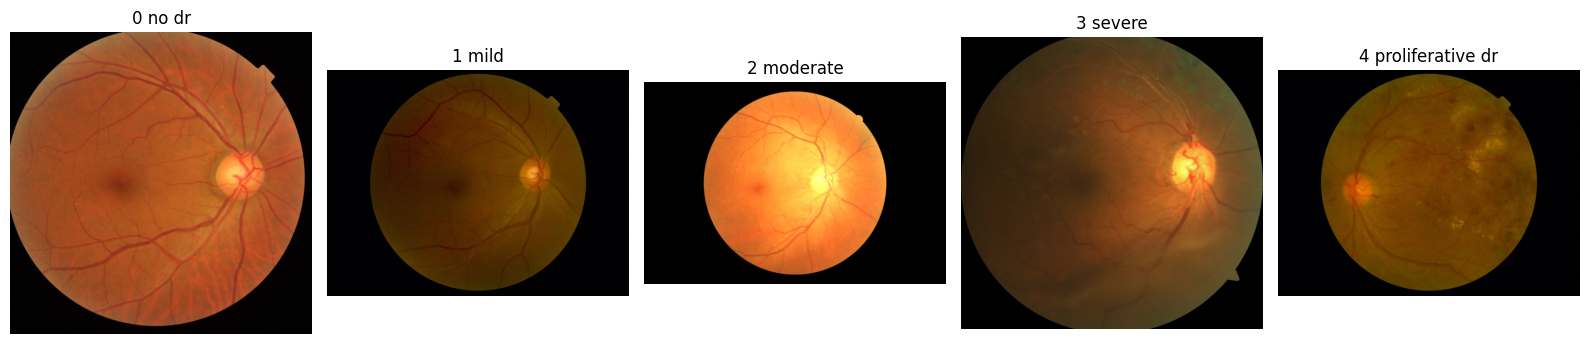

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, class_name in enumerate(class_names):
    folder = os.path.join(dataset_path, class_name)
    image_files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder, image_files[0])

    with Image.open(image_path) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(class_name.replace("class_", "").replace("_", " "))
    axes[i].axis("off")

plt.tight_layout()
plt.show()

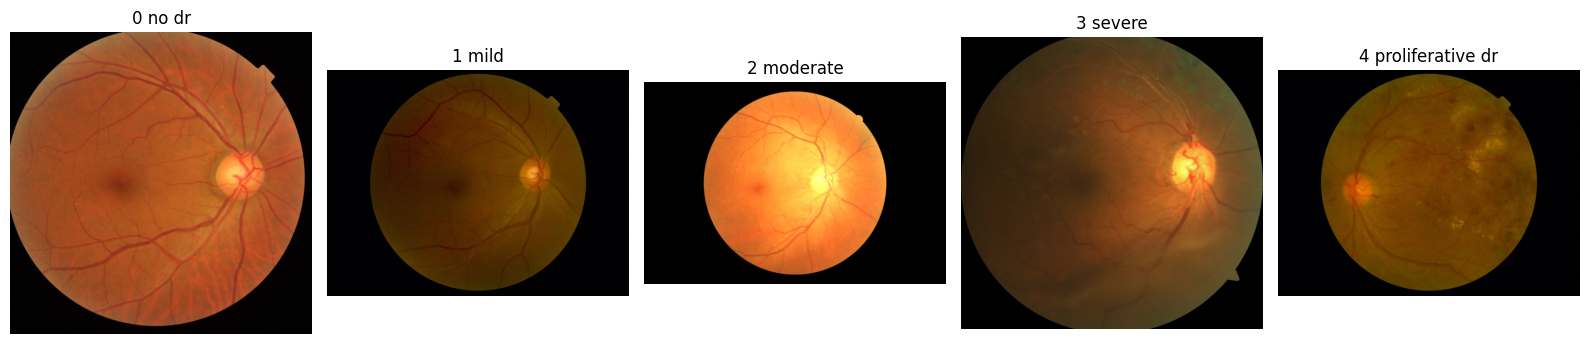

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, class_name in enumerate(class_names):
    folder = os.path.join(dataset_path, class_name)
    image_files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder, image_files[0])

    with Image.open(image_path) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(class_name.replace("class_", "").replace("_", " "))
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

dataset_path = Path("/content/retina_dataset/balanced")
SEED = 42

records = []

for class_name in sorted(p.name for p in dataset_path.iterdir() if p.is_dir()):
    class_folder = dataset_path / class_name

    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            records.append({
                "image_path": str(image_path),
                "class_name": class_name
            })

df = pd.DataFrame(records)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_name"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_name"],
    random_state=SEED
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining distribution:")
print(train_df["class_name"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class_name"].value_counts().sort_index())

Training images: 826
Validation images: 177
Test images: 177

Training distribution:
class_name
class_0_no_dr               165
class_1_mild                166
class_2_moderate            165
class_3_severe              165
class_4_proliferative_dr    165
Name: count, dtype: int64

Validation distribution:
class_name
class_0_no_dr               35
class_1_mild                35
class_2_moderate            36
class_3_severe              35
class_4_proliferative_dr    36
Name: count, dtype: int64

Test distribution:
class_name
class_0_no_dr               36
class_1_mild                35
class_2_moderate            35
class_3_severe              36
class_4_proliferative_dr    35
Name: count, dtype: int64


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import numpy as np
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

class_names = sorted(train_df["class_name"].unique())

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3,
        try_recover_truncated=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["class_name"].map(class_to_index).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Classes:", class_to_index)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Classes: {'class_0_no_dr': 0, 'class_1_mild': 1, 'class_2_moderate': 2, 'class_3_severe': 3, 'class_4_proliferative_dr': 4}
Training batches: 52
Validation batches: 12
Test batches: 12


Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)


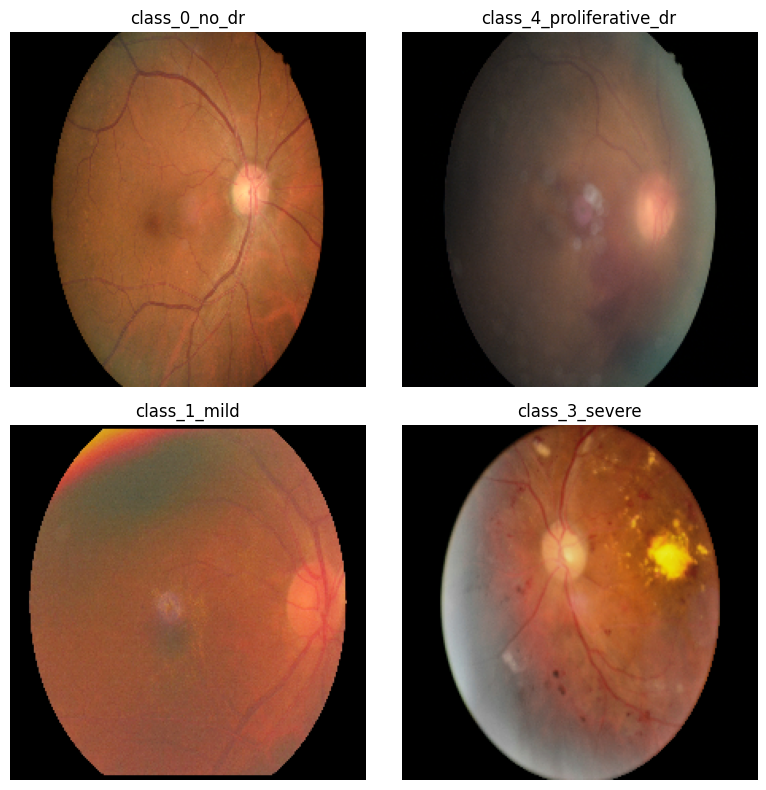

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

plt.figure(figsize=(8, 8))

for i in range(min(4, len(images))):
    plt.subplot(2, 2, i + 1)
    plt.imshow(tf.cast(images[i], tf.uint8).numpy())
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = 5
IMG_SIZE = (224, 224)

# Load the pretrained EfficientNet-B0 feature extractor
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Initially freeze the pretrained layers
base_model.trainable = False

# Build our classification model
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt

os.makedirs("/content/retina_outputs", exist_ok=True)

checkpoint_path = "/content/retina_outputs/best_efficientnetb0.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.2598 - loss: 1.6317
Epoch 1: val_loss improved from None to 1.37029, saving model to /content/retina_outputs/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/retina_outputs/best_efficientnetb0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.3341 - loss: 1.5002 - val_accuracy: 0.3785 - val_loss: 1.3703 - learning_rate: 0.0010
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.4637 - loss: 1.2775
Epoch 2: val_loss improved from 1.37029 to 1.30032, saving model to /content/retina_outputs/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/retina_outputs/best_efficientnetb0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 22s 433ms/step - accuracy: 0.4564 - loss: 1.2862 - val_accuracy: 0.3955 - val_loss: 1.3003 - learning_rate: 0.0010
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.5193 - loss: 1.1854
Epoch 3: val_loss improved from 1.30032 to 1.22084, saving

In [ ]:
for epoch, (train_acc, val_acc) in enumerate(
    zip(history.history["accuracy"],
        history.history["val_accuracy"]), start=1
):
    print(
        f"Epoch {epoch}: "
        f"Training Accuracy = {train_acc * 100:.2f}%, "
        f"Validation Accuracy = {val_acc * 100:.2f}%"
    )

Epoch 1: Training Accuracy = 33.41%, Validation Accuracy = 37.85%
Epoch 2: Training Accuracy = 45.64%, Validation Accuracy = 39.55%
Epoch 3: Training Accuracy = 50.00%, Validation Accuracy = 47.46%
Epoch 4: Training Accuracy = 49.76%, Validation Accuracy = 47.46%
Epoch 5: Training Accuracy = 54.12%, Validation Accuracy = 46.89%
Epoch 6: Training Accuracy = 57.02%, Validation Accuracy = 49.72%
Epoch 7: Training Accuracy = 55.93%, Validation Accuracy = 48.59%
Epoch 8: Training Accuracy = 58.11%, Validation Accuracy = 49.72%
Epoch 9: Training Accuracy = 59.69%, Validation Accuracy = 53.11%
Epoch 10: Training Accuracy = 60.41%, Validation Accuracy = 53.11%


Epoch 1: Train Accuracy = 33.41%, Val Accuracy = 37.85%, Train Loss = 1.5002, Val Loss = 1.3703
Epoch 2: Train Accuracy = 45.64%, Val Accuracy = 39.55%, Train Loss = 1.2862, Val Loss = 1.3003
Epoch 3: Train Accuracy = 50.00%, Val Accuracy = 47.46%, Train Loss = 1.2083, Val Loss = 1.2208
Epoch 4: Train Accuracy = 49.76%, Val Accuracy = 47.46%, Train Loss = 1.1567, Val Loss = 1.2134
Epoch 5: Train Accuracy = 54.12%, Val Accuracy = 46.89%, Train Loss = 1.1190, Val Loss = 1.2010
Epoch 6: Train Accuracy = 57.02%, Val Accuracy = 49.72%, Train Loss = 1.1007, Val Loss = 1.1533
Epoch 7: Train Accuracy = 55.93%, Val Accuracy = 48.59%, Train Loss = 1.0593, Val Loss = 1.1639
Epoch 8: Train Accuracy = 58.11%, Val Accuracy = 49.72%, Train Loss = 1.0334, Val Loss = 1.1456
Epoch 9: Train Accuracy = 59.69%, Val Accuracy = 53.11%, Train Loss = 0.9976, Val Loss = 1.1329
Epoch 10: Train Accuracy = 60.41%, Val Accuracy = 53.11%, Train Loss = 1.0081, Val Loss = 1.1134


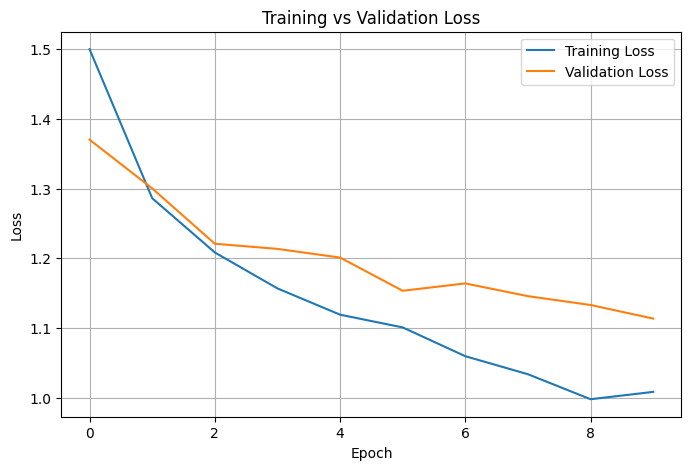

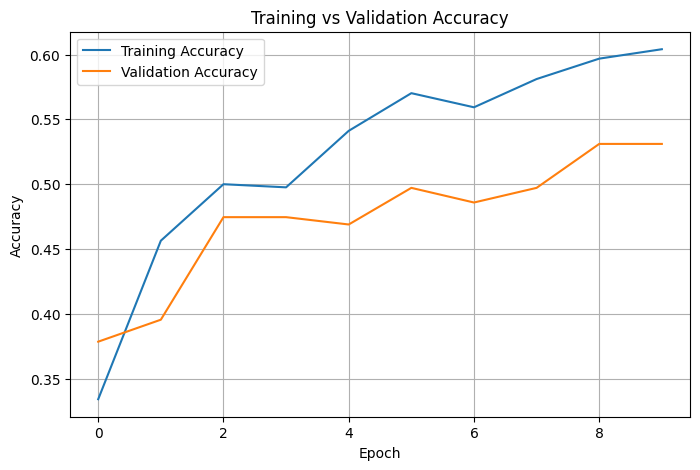

In [ ]:
import matplotlib.pyplot as plt

# Print accuracy and loss for every epoch
for epoch in range(len(history.history["loss"])):
    print(
        f"Epoch {epoch + 1}: "
        f"Train Accuracy = {history.history['accuracy'][epoch] * 100:.2f}%, "
        f"Val Accuracy = {history.history['val_accuracy'][epoch] * 100:.2f}%, "
        f"Train Loss = {history.history['loss'][epoch]:.4f}, "
        f"Val Loss = {history.history['val_loss'][epoch]:.4f}"
    )

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Keep the best checkpoint and allow training to continue
callbacks_30 = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Continue from the current model weights
history_more = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=10,
    epochs=30,
    callbacks=callbacks_30
)

Epoch 11/30
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.6492 - loss: 0.9367
Epoch 11: val_loss improved from None to 1.12844, saving model to /content/retina_outputs/best_efficientnetb0.keras

Epoch 11: finished saving model to /content/retina_outputs/best_efficientnetb0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 25s 470ms/step - accuracy: 0.5944 - loss: 0.9902 - val_accuracy: 0.5141 - val_loss: 1.1284 - learning_rate: 0.0010
Epoch 12/30
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.6091 - loss: 0.9795
Epoch 12: val_loss improved from 1.12844 to 1.09895, saving model to /content/retina_outputs/best_efficientnetb0.keras

Epoch 12: finished saving model to /content/retina_outputs/best_efficientnetb0.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 20s 389ms/step - accuracy: 0.6029 - loss: 0.9889 - val_accuracy: 0.5311 - val_loss: 1.0989 - learning_rate: 0.0010
Epoch 13/30
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.6008 - loss: 0.9770
Epoch 13: val_loss improved from 1.09895 to 1.09

In [ ]:
# Combine results from the first 10 epochs and the continuation
all_history = {
    key: history.history[key] + history_more.history[key]
    for key in history.history
}

# Print all epoch results
print("EPOCH | TRAIN ACC | VAL ACC | TRAIN LOSS | VAL LOSS")
print("-" * 58)

for i in range(len(all_history["loss"])):
    print(
        f"{i + 1:5d} | "
        f"{all_history['accuracy'][i] * 100:8.2f}% | "
        f"{all_history['val_accuracy'][i] * 100:7.2f}% | "
        f"{all_history['loss'][i]:10.4f} | "
        f"{all_history['val_loss'][i]:8.4f}"
    )

EPOCH | TRAIN ACC | VAL ACC | TRAIN LOSS | VAL LOSS
----------------------------------------------------------
    1 |    33.41% |   37.85% |     1.5002 |   1.3703
    2 |    45.64% |   39.55% |     1.2862 |   1.3003
    3 |    50.00% |   47.46% |     1.2083 |   1.2208
    4 |    49.76% |   47.46% |     1.1567 |   1.2134
    5 |    54.12% |   46.89% |     1.1190 |   1.2010
    6 |    57.02% |   49.72% |     1.1007 |   1.1533
    7 |    55.93% |   48.59% |     1.0593 |   1.1639
    8 |    58.11% |   49.72% |     1.0334 |   1.1456
    9 |    59.69% |   53.11% |     0.9976 |   1.1329
   10 |    60.41% |   53.11% |     1.0081 |   1.1134
   11 |    59.44% |   51.41% |     0.9902 |   1.1284
   12 |    60.29% |   53.11% |     0.9889 |   1.0989
   13 |    61.38% |   53.67% |     0.9426 |   1.0941
   14 |    58.72% |   53.11% |     0.9604 |   1.1128
   15 |    61.86% |   54.24% |     0.9409 |   1.0995
   16 |    62.23% |   53.11% |     0.9288 |   1.0768
   17 |    66.71% |   54.24% |     0.8958

In [ ]:
# Evaluate the model on unseen test images
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n========== TEST RESULTS ==========")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 446ms/step - accuracy: 0.5932 - loss: 1.0197

========== TEST RESULTS ==========
Test Accuracy : 59.32%
Test Loss     : 1.0197


12/12 ━━━━━━━━━━━━━━━━━━━━ 20s 802ms/step
CLASSIFICATION REPORT

                          precision    recall  f1-score   support

           class_0_no_dr       0.63      0.67      0.65        36
            class_1_mild       0.57      0.60      0.58        35
        class_2_moderate       0.48      0.31      0.38        35
          class_3_severe       0.57      0.56      0.56        36
class_4_proliferative_dr       0.66      0.83      0.73        35

                accuracy                           0.59       177
               macro avg       0.58      0.59      0.58       177
            weighted avg       0.58      0.59      0.58       177



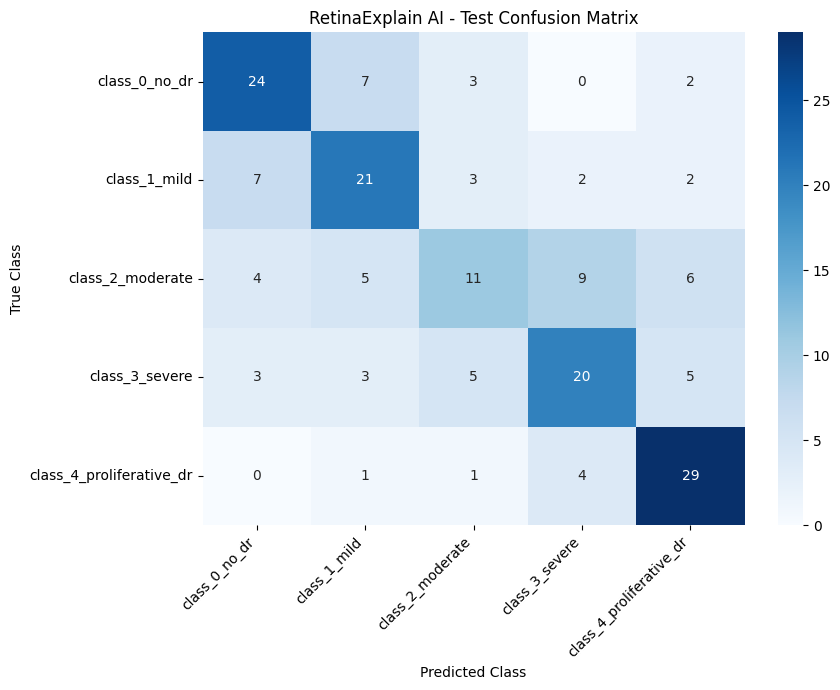

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Get the true labels and model predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Class names in the same order as class indices
class_names = [
    name for name, index in
    sorted(class_to_index.items(), key=lambda item: item[1])
]

# Print performance for each class
print("CLASSIFICATION REPORT\n")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("RetinaExplain AI - Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

save_dir = "/content/drive/MyDrive/RetinaExplain_AI/Models"
os.makedirs(save_dir, exist_ok=True)

print("Model folder:", save_dir)

Model folder: /content/drive/MyDrive/RetinaExplain_AI/Models


In [ ]:
model_path = os.path.join(save_dir, "retina_efficientnetb0.keras")

model.save(model_path)

print("Complete model saved to:", model_path)

Complete model saved to: /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0.keras


In [ ]:
weights_path = os.path.join(save_dir, "retina_efficientnetb0.weights.h5")

model.save_weights(weights_path)

print("Model weights saved to:", weights_path)

Model weights saved to: /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0.weights.h5


In [ ]:
for path in [model_path, weights_path]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"Saved: {os.path.basename(path)} — {size_mb:.2f} MB")
    else:
        print("File missing:", path)

Saved: retina_efficientnetb0.keras — 16.33 MB
Saved: retina_efficientnetb0.weights.h5 — 16.12 MB


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os
import shutil

# Create Kaggle's configuration folder
os.makedirs("/root/.kaggle", exist_ok=True)

# Move the uploaded credentials into the correct location
source = "/content/kaggle.json"
destination = "/root/.kaggle/kaggle.json"

if os.path.exists(source):
    shutil.move(source, destination)
    os.chmod(destination, 0o600)
    print("Kaggle credentials configured successfully.")
else:
    print("kaggle.json not found. Please upload it again.")

Kaggle credentials configured successfully.


In [ ]:
!pip install -q kaggle
!kaggle datasets list -s "diabetic retinopathy"

ref                                                           title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
tanlikesmath/diabetic-retinopathy-resized                     Diabetic Retinopathy (resized)                       7785957896  2019-05-08 01:48:17.993000          35545        593  0.5882353        
sovitrath/diabetic-retinopathy-224x224-gaussian-filtered      Diabetic Retinopathy 224x224 Gaussian Filtered        447582906  2020-02-18 02:33:27.540000          28318        255  0.88235295       
sachinkumar413/diabetic-retinopathy-dataset                   Diabetic Retinopathy Dataset                          367332292  2022-04-24 16:55:11.840000           8151         73  0.75             
pkdar

In [ ]:
import os

kaggle_dir = "/content/retina_kaggle_aptos"
os.makedirs(kaggle_dir, exist_ok=True)

!kaggle datasets download \
    -d sovitrath/diabetic-retinopathy-224x224-2019-data \
    -p /content/retina_kaggle_aptos \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data
License(s): CC0-1.0
100% 238M/238M [00:03<00:00, 82.9MB/s]



In [ ]:
from pathlib import Path

root = Path("/content/retina_kaggle_aptos")

for folder in sorted(p for p in root.rglob("*") if p.is_dir()):
    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png"]
    ]

    if images:
        print(f"{folder.name}: {len(images)} images")

Mild: 370 images
Moderate: 999 images
No_DR: 1805 images
Proliferate_DR: 295 images
Severe: 193 images


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

old_root = Path("/content/retina_dataset/balanced")
new_root = Path("/content/retina_kaggle_aptos")

def image_hashes(root):
    hashes = defaultdict(list)

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png"
        }:
            digest = hashlib.md5(path.read_bytes()).hexdigest()
            hashes[digest].append(str(path))

    return hashes

old_hashes = image_hashes(old_root)
new_hashes = image_hashes(new_root)

duplicates = set(old_hashes) & set(new_hashes)

print("Existing dataset images:", sum(map(len, old_hashes.values())))
print("Kaggle dataset images:", sum(map(len, new_hashes.values())))
print("Shared exact image hashes:", len(duplicates))

if duplicates:
    print("\nExamples:")
    for digest in list(duplicates)[:5]:
        print("Existing:", old_hashes[digest][0])
        print("Kaggle:  ", new_hashes[digest][0])

Existing dataset images: 1180
Kaggle dataset images: 3662
Shared exact image hashes: 0


In [ ]:
!pip install -q ImageHash


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.4 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from PIL import Image
import imagehash

old_root = Path("/content/retina_dataset/balanced")
new_root = Path("/content/retina_kaggle_aptos")

extensions = {".jpg", ".jpeg", ".png"}

old_images = [
    p for p in old_root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

new_images = [
    p for p in new_root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

def get_phash(path):
    try:
        with Image.open(path) as img:
            return int(str(imagehash.phash(img.convert("RGB"))), 16)
    except Exception:
        return None

old_hashes = [(p, get_phash(p)) for p in old_images]
new_hashes = [(p, get_phash(p)) for p in new_images]

old_hashes = [(p, h) for p, h in old_hashes if h is not None]
new_hashes = [(p, h) for p, h in new_hashes if h is not None]

# Find close perceptual-hash matches.
# A Hamming distance <= 5 is a candidate for manual inspection.
matches = []

for old_path, old_hash in old_hashes:
    for new_path, new_hash in new_hashes:
        distance = (old_hash ^ new_hash).bit_count()

        if distance <= 5:
            matches.append((distance, old_path, new_path))

matches.sort(key=lambda item: item[0])

print("Existing images checked:", len(old_hashes))
print("Kaggle images checked:", len(new_hashes))
print("Potential near-duplicate pairs:", len(matches))

for distance, old_path, new_path in matches[:20]:
    print(f"\nDistance: {distance}")
    print("Existing:", old_path)
    print("Kaggle:  ", new_path)

Existing images checked: 1180
Kaggle images checked: 3662
Potential near-duplicate pairs: 96

Distance: 2
Existing: /content/retina_dataset/balanced/class_0_no_dr/41.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_DR/7526c59c36d3.png

Distance: 2
Existing: /content/retina_dataset/balanced/class_0_no_dr/96.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_DR/de4cdabbce6d.png

Distance: 2
Existing: /content/retina_dataset/balanced/class_1_mild/205.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_DR/a76132e79688.png

Distance: 2
Existing: /content/retina_dataset/balanced/class_3_severe/133.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_DR/6bf2a81a5d91.png

Distance: 4
Existing: /content/retina_dataset/balanced/class_0_no_dr/33.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_DR/ad93d88c87ea.png

Distance: 4
Existing: /content/retina_dataset/balanced/class_0_no_dr/33.jpg
Kaggle:   /content/retina_kaggle_aptos/colored_images/No_D

Strong candidate pairs: 4


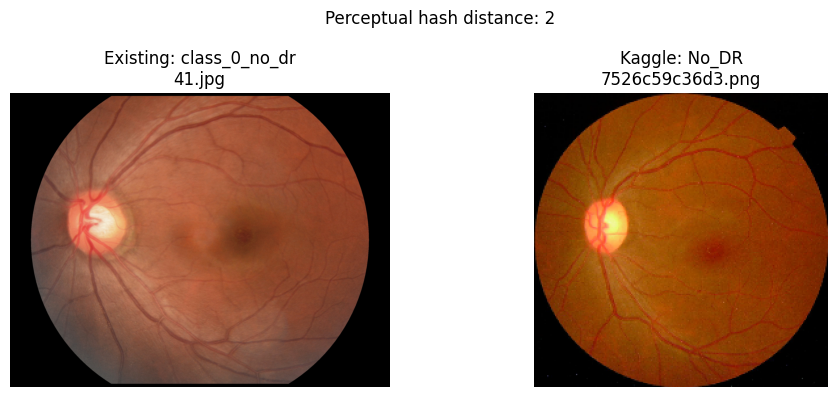

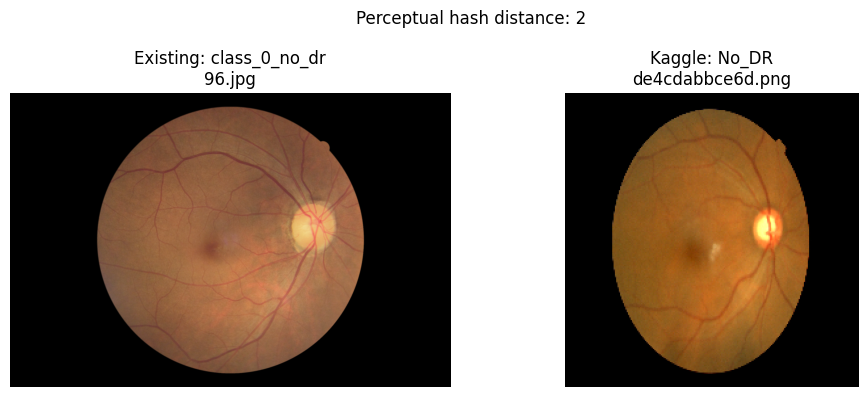

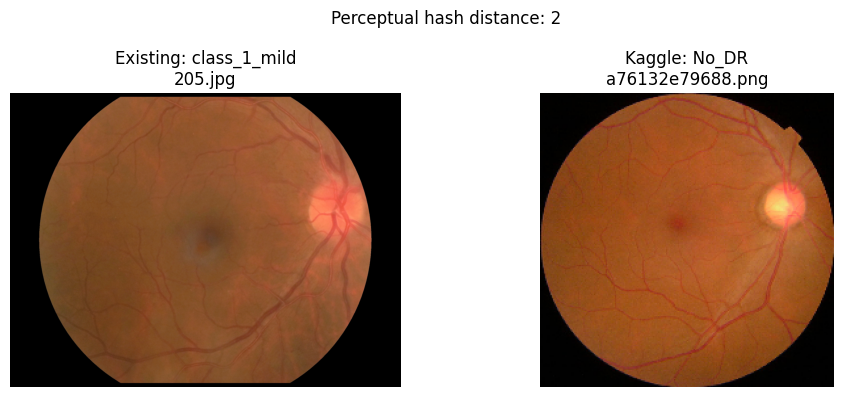

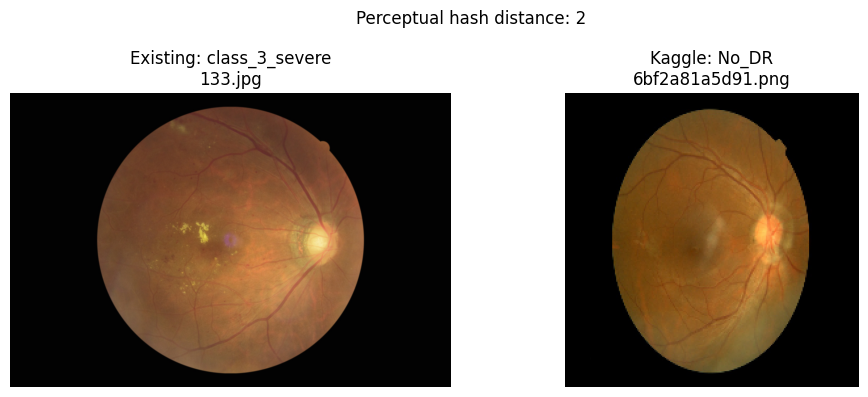

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Show the closest potential matches first
strong_matches = [m for m in matches if m[0] <= 2]

print("Strong candidate pairs:", len(strong_matches))

if not strong_matches:
    print("No pairs with distance <= 2. Inspect pairs with distance <= 5.")
else:
    for distance, old_path, new_path in strong_matches:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        with Image.open(old_path) as img:
            axes[0].imshow(img.convert("RGB"))
        axes[0].set_title(
            f"Existing: {old_path.parent.name}\n{old_path.name}"
        )
        axes[0].axis("off")

        with Image.open(new_path) as img:
            axes[1].imshow(img.convert("RGB"))
        axes[1].set_title(
            f"Kaggle: {new_path.parent.name}\n{new_path.name}"
        )
        axes[1].axis("off")

        fig.suptitle(f"Perceptual hash distance: {distance}")
        plt.tight_layout()
        plt.show()

In [ ]:
from pathlib import Path
import shutil

# Existing dataset
old_root = Path("/content/retina_dataset/balanced")

# Kaggle dataset
kaggle_root = Path(
    "/content/retina_kaggle_aptos/colored_images"
)

# New combined dataset (separate from both original datasets)
combined_root = Path(
    "/content/retina_dataset/combined_v1"
)

# Existing class name -> Kaggle class name
class_map = {
    "class_0_no_dr": "No_DR",
    "class_1_mild": "Mild",
    "class_2_moderate": "Moderate",
    "class_3_severe": "Severe",
    "class_4_proliferative_dr": "Proliferate_DR",
}

image_extensions = {".jpg", ".jpeg", ".png"}

for old_class, kaggle_class in class_map.items():

    old_folder = old_root / old_class
    kaggle_folder = kaggle_root / kaggle_class
    output_folder = combined_root / old_class

    if not old_folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {old_folder}")

    if not kaggle_folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {kaggle_folder}")

    output_folder.mkdir(parents=True, exist_ok=True)

    # Copy existing dataset images
    for path in old_folder.iterdir():
        if path.is_file() and path.suffix.lower() in image_extensions:
            shutil.copy2(
                path,
                output_folder / f"old_{path.name}"
            )

    # Copy Kaggle dataset images
    for path in kaggle_folder.iterdir():
        if path.is_file() and path.suffix.lower() in image_extensions:
            shutil.copy2(
                path,
                output_folder / f"kaggle_{path.name}"
            )

    print(f"Combined class: {old_class}")

print("\nDataset combining completed.")
print("Location:", combined_root)

Combined class: class_0_no_dr
Combined class: class_1_mild
Combined class: class_2_moderate
Combined class: class_3_severe
Combined class: class_4_proliferative_dr

Dataset combining completed.
Location: /content/retina_dataset/combined_v1


In [ ]:
import pandas as pd
from pathlib import Path

train_csv = Path("/content/retina_dataset/splits/train.csv")

if not train_csv.exists():
    print("Training CSV not found. We need to recreate the dataset split.")
else:
    train_df = pd.read_csv(train_csv)

    print("Columns:", train_df.columns.tolist())
    print("\nFirst 5 rows:")
    display(train_df.head())

Training CSV not found. We need to recreate the dataset split.


In [ ]:
from pathlib import Path

for class_folder in sorted(combined_root.iterdir()):
    if class_folder.is_dir():
        count = sum(
            1 for p in class_folder.iterdir()
            if p.is_file() and p.suffix.lower()
            in {".jpg", ".jpeg", ".png"}
        )
        print(f"{class_folder.name}: {count} images")

total = sum(
    1 for p in combined_root.rglob("*")
    if p.is_file() and p.suffix.lower()
    in {".jpg", ".jpeg", ".png"}
)

print("\nTOTAL IMAGES:", total)

class_0_no_dr: 2041 images
class_1_mild: 606 images
class_2_moderate: 1235 images
class_3_severe: 429 images
class_4_proliferative_dr: 531 images

TOTAL IMAGES: 4842


In [ ]:
import pandas as pd
from pathlib import Path

train_csv = Path("/content/retina_dataset/splits/train.csv")

if not train_csv.exists():
    print("Training CSV not found. We need to recreate the dataset split.")
else:
    train_df = pd.read_csv(train_csv)

    print("Columns:", train_df.columns.tolist())
    print("\nFirst 5 rows:")
    display(train_df.head())

Training CSV not found. We need to recreate the dataset split.


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Create a consistent mapping from class names to integer labels
class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

# Convert training labels into integer IDs
y_train = train_df["label"].map(class_to_index).to_numpy()

# Calculate balanced weights using training data only
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weight = {
    int(index): float(weight)
    for index, weight in enumerate(weights)
}

print("Class weights:")
for name, index in class_to_index.items():
    print(f"{name}: {class_weight[index]:.3f}")

KeyError: 'label'

In [ ]:
import pandas as pd
from pathlib import Path

train_csv = Path("/content/retina_dataset/splits/train.csv")

if not train_csv.exists():
    print("Training CSV not found. We need to recreate the dataset split.")
else:
    train_df = pd.read_csv(train_csv)

    print("Columns:", train_df.columns.tolist())
    print("\nFirst 5 rows:")
    display(train_df.head())

Training CSV not found. We need to recreate the dataset split.


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get the five class names
class_names = sorted(train_df["label"].unique())

# Map each class name to an integer
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

# Convert labels to integers
y_train = train_df["label"].map(class_to_index).to_numpy()

# Calculate weights using the training split only
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weight = {
    int(i): float(weight)
    for i, weight in enumerate(weights)
}

print("Class weights:")
for name, index in class_to_index.items():
    print(f"{name}: {class_weight[index]:.3f}")

KeyError: 'label'

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight

# Step 1: Reload the saved training split
train_csv = Path("/content/retina_dataset/splits/train.csv")

if not train_csv.exists():
    raise FileNotFoundError(
        f"Training CSV not found: {train_csv}\n"
        "We need to recreate the dataset splits."
    )

train_df = pd.read_csv(train_csv)
train_df.columns = train_df.columns.str.strip()

print("CSV columns:", train_df.columns.tolist())

# Step 2: Find the image-path column
path_column = next(
    (col for col in ["path", "image_path", "filepath", "file_path"]
     if col in train_df.columns),
    None
)

# Reconstruct labels from folder names if label is missing
if "label" not in train_df.columns:
    if path_column is None:
        raise ValueError(
            "Could not find a label or image-path column. "
            "Check the CSV columns printed above."
        )

    train_df["label"] = train_df[path_column].apply(
        lambda p: Path(str(p)).parent.name
    )

# Step 3: Check the labels
print("\nTraining class counts:")
print(train_df["label"].value_counts())

# Step 4: Calculate class weights
class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

y_train = train_df["label"].map(class_to_index).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weight = {
    int(index): float(weight)
    for index, weight in enumerate(weights)
}

print("\nCalculated class weights:")
for name, index in class_to_index.items():
    print(f"{name}: {class_weight[index]:.3f}")

FileNotFoundError: Training CSV not found: /content/retina_dataset/splits/train.csv
We need to recreate the dataset splits.

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Locate the combined dataset
combined_root = Path("/content/retina_dataset/combined_v1")

if not combined_root.is_dir():
    raise FileNotFoundError(
        f"Combined dataset folder not found: {combined_root}\n"
        "Check whether the Colab runtime was restarted."
    )

# 2. Read and validate images
image_extensions = {".jpg", ".jpeg", ".png"}
records = []
invalid_files = []

for class_folder in sorted(combined_root.iterdir()):
    if not class_folder.is_dir():
        continue

    label = class_folder.name

    for path in class_folder.iterdir():
        if path.is_file() and path.suffix.lower() in image_extensions:
            try:
                with Image.open(path) as img:
                    img.verify()

                records.append({
                    "path": str(path),
                    "label": label
                })

            except Exception:
                invalid_files.append(str(path))

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No valid images were found in the combined dataset.")

print("Valid images:", len(df))
print("Invalid images:", len(invalid_files))

# 3. Create stratified train / validation / test splits
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# 4. Save the split CSV files
split_dir = Path("/content/retina_dataset/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "validation.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("\nSplit sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# 5. Calculate class weights using training data only
class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

y_train = train_df["label"].map(class_to_index).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weight = {
    int(index): float(weight)
    for index, weight in enumerate(weights)
}

print("\nClass distribution in training data:")
print(train_df["label"].value_counts().sort_index())

print("\nCalculated class weights:")
for name, index in class_to_index.items():
    print(f"{name}: {class_weight[index]:.3f}")

print("\nSaved split files to:", split_dir)

Valid images: 4842
Invalid images: 0

Split sizes:
Training: 3389
Validation: 726
Testing: 727

Class distribution in training data:
label
class_0_no_dr               1429
class_1_mild                 424
class_2_moderate             864
class_3_severe               300
class_4_proliferative_dr     372
Name: count, dtype: int64

Calculated class weights:
class_0_no_dr: 0.474
class_1_mild: 1.599
class_2_moderate: 0.784
class_3_severe: 2.259
class_4_proliferative_dr: 1.822

Saved split files to: /content/retina_dataset/splits


In [ ]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Convert class names to integer IDs
class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print("Class mapping:")
print(class_to_index)


# Load and preprocess JPEG or PNG images
def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


# Convert a DataFrame into a TensorFlow dataset
def make_dataset(dataframe, training=False):
    paths = dataframe["path"].astype(str).to_numpy()

    labels = dataframe["label"].map(
        class_to_index
    ).to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Build all three datasets
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("\nDatasets created successfully.")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Class mapping:
{'class_0_no_dr': 0, 'class_1_mild': 1, 'class_2_moderate': 2, 'class_3_severe': 3, 'class_4_proliferative_dr': 4}

Datasets created successfully.
Training images: 3389
Validation images: 726
Test images: 727


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)
import os

NUM_CLASSES = len(class_names)

# Preserve the previous model; create a new model for v2
base_model_v2 = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model_v2.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model_v2(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model_v2 = models.Model(inputs, outputs)

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Mount Google Drive if necessary
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/RetinaExplain_AI/Models"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(
    save_dir,
    "retina_efficientnetb0_v2_best.keras"
)

callbacks_v2 = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=callbacks_v2
)

Epoch 1/30
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.4085 - loss: 1.4685
Epoch 1: val_loss improved from None to 1.02842, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_best.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 79s 259ms/step - accuracy: 0.5034 - loss: 1.3189 - val_accuracy: 0.6019 - val_loss: 1.0284 - learning_rate: 0.0010
Epoch 2/30
211/212 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.6161 - loss: 1.1351
Epoch 2: val_loss improved from 1.02842 to 0.89694, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_best.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 27s 127ms/step - accuracy: 0.6214 - loss: 1.1089 - val_accuracy: 0.6832 - val_loss: 0.8969 - learning_rate: 0.0010
Ep

In [ ]:
import tensorflow as tf

checkpoint_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "retina_efficientnetb0_v2_best.keras"
)

best_model = tf.keras.models.load_model(checkpoint_path)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

46/46 ━━━━━━━━━━━━━━━━━━━━ 33s 280ms/step - accuracy: 0.7331 - loss: 0.7598
Test Loss: 0.7598
Test Accuracy: 73.31%


In [ ]:
import os
import tensorflow as tf

# Folder in Google Drive
save_dir = "/content/drive/MyDrive/RetinaExplain_AI/Models"
os.makedirs(save_dir, exist_ok=True)

# Save the evaluated model
final_model_path = os.path.join(
    save_dir,
    "RetinaExplain_AI_v2_final.keras"
)

best_model.save(final_model_path)

print("Model saved successfully!")
print("Location:", final_model_path)
print("Test Accuracy: 73.31%")

Model saved successfully!
Location: /content/drive/MyDrive/RetinaExplain_AI/Models/RetinaExplain_AI_v2_final.keras
Test Accuracy: 73.31%


In [ ]:
import os

if os.path.exists(final_model_path):
    print("Verified: model file exists.")
    print("File size:", round(
        os.path.getsize(final_model_path) / (1024 * 1024), 2
    ), "MB")
else:
    print("Model file not found. Check the Drive path.")

Verified: model file exists.
File size: 16.32 MB


Class order: ['class_0_no_dr', 'class_1_mild', 'class_2_moderate', 'class_3_severe', 'class_4_proliferative_dr']

Classification Report:

                          precision    recall  f1-score   support

           class_0_no_dr     0.8981    0.9510    0.9238       306
            class_1_mild     0.5821    0.4286    0.4937        91
        class_2_moderate     0.6633    0.7027    0.6824       185
          class_3_severe     0.4625    0.5692    0.5103        65
class_4_proliferative_dr     0.6780    0.5063    0.5797        79

                accuracy                         0.7397       726
               macro avg     0.6568    0.6316    0.6380       726
            weighted avg     0.7357    0.7397    0.7339       726



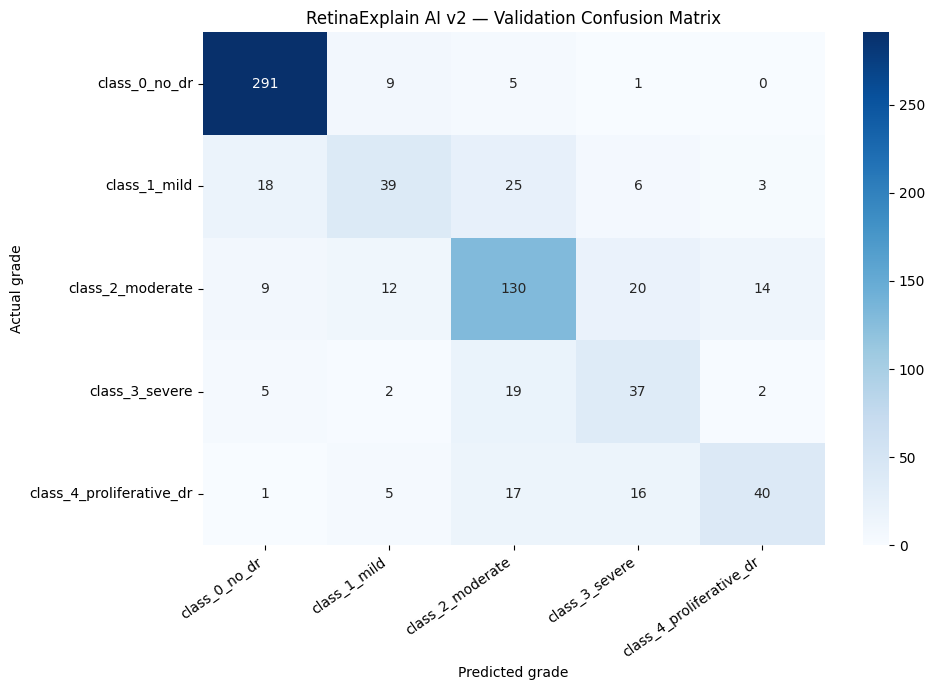

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Predict on the validation dataset
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Class names in the same order as the model's output
print("Class order:", class_names)

# Detailed metrics for each DR grade
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted grade")
plt.ylabel("Actual grade")
plt.title("RetinaExplain AI v2 — Validation Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

import tensorflow as tf

# Find the EfficientNetB0 backbone inside the model
for layer in best_model.layers:
    print(layer.name, type(layer).__name__)

input_layer_3 InputLayer
efficientnetb0 Functional
global_average_pooling2d_1 GlobalAveragePooling2D
dropout_1 Dropout
dense_1 Dense


In [ ]:

# Get the backbone layer
base_model = best_model.get_layer("efficientnetb0")

# Enable fine-tuning
base_model.trainable = True

# Freeze earlier layers; train only the later layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))


Trainable layers: 23


In [ ]:

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)
import os

fine_tune_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "retina_efficientnetb0_v2_finetuned.keras"
)

fine_tune_callbacks = [
    ModelCheckpoint(
        fine_tune_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=fine_tune_callbacks
)

Epoch 1/12
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.7209 - loss: 0.8407
Epoch 1: val_loss improved from None to 0.76736, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_finetuned.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 79s 237ms/step - accuracy: 0.7049 - loss: 0.8606 - val_accuracy: 0.7052 - val_loss: 0.7674 - learning_rate: 1.0000e-05
Epoch 2/12
211/212 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.6933 - loss: 0.8564
Epoch 2: val_loss improved from 0.76736 to 0.74674, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_efficientnetb0_v2_finetuned.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 27s 127ms/step - accuracy: 0.7026 - loss: 0.8511 - val_accuracy: 0.7231 - val_loss: 0.7467 -

In [ ]:

import os
import tensorflow as tf

save_dir = "/content/drive/MyDrive/RetinaExplain_AI/Models"
os.makedirs(save_dir, exist_ok=True)

# Load the best fine-tuned checkpoint
best_finetuned_model = tf.keras.models.load_model(
    os.path.join(
        save_dir,
        "retina_efficientnetb0_v2_finetuned.keras"
    )
)

# Save with validation metrics in the filename
final_path = os.path.join(
    save_dir,
    "RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras"
)

best_finetuned_model.save(final_path)

print("Model saved successfully!")
print("File:", final_path)
print("Selected epoch: 11")
print("Validation accuracy: 74.24%")
print("Validation loss: 0.70979")

Model saved successfully!
File: /content/drive/MyDrive/RetinaExplain_AI/Models/RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras
Selected epoch: 11
Validation accuracy: 74.24%
Validation loss: 0.70979


                          precision    recall  f1-score   support

           class_0_no_dr     0.9316    0.9346    0.9331       306
            class_1_mild     0.5042    0.6593    0.5714        91
        class_2_moderate     0.7152    0.6108    0.6589       185
          class_3_severe     0.5068    0.5692    0.5362        65
class_4_proliferative_dr     0.6232    0.5443    0.5811        79

                accuracy                         0.7424       726
               macro avg     0.6562    0.6637    0.6561       726
            weighted avg     0.7513    0.7424    0.7441       726



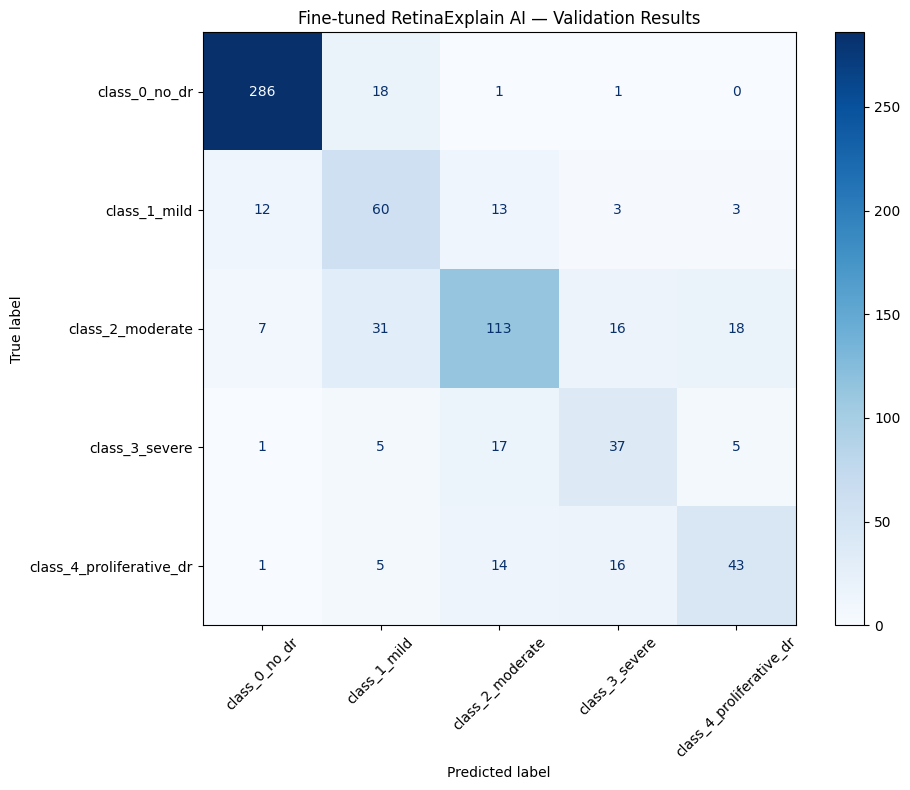

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Use the fine-tuned model loaded from your saved checkpoint
y_true_fine = []
y_pred_fine = []

for images, labels in val_ds:
    probs = best_finetuned_model.predict(images, verbose=0)
    y_true_fine.extend(labels.numpy())
    y_pred_fine.extend(np.argmax(probs, axis=1))

labels_order = list(range(len(class_names)))

print(classification_report(
    y_true_fine,
    y_pred_fine,
    labels=labels_order,
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true_fine,
    y_pred_fine,
    labels=labels_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Fine-tuned RetinaExplain AI — Validation Results")
plt.tight_layout()
plt.show()

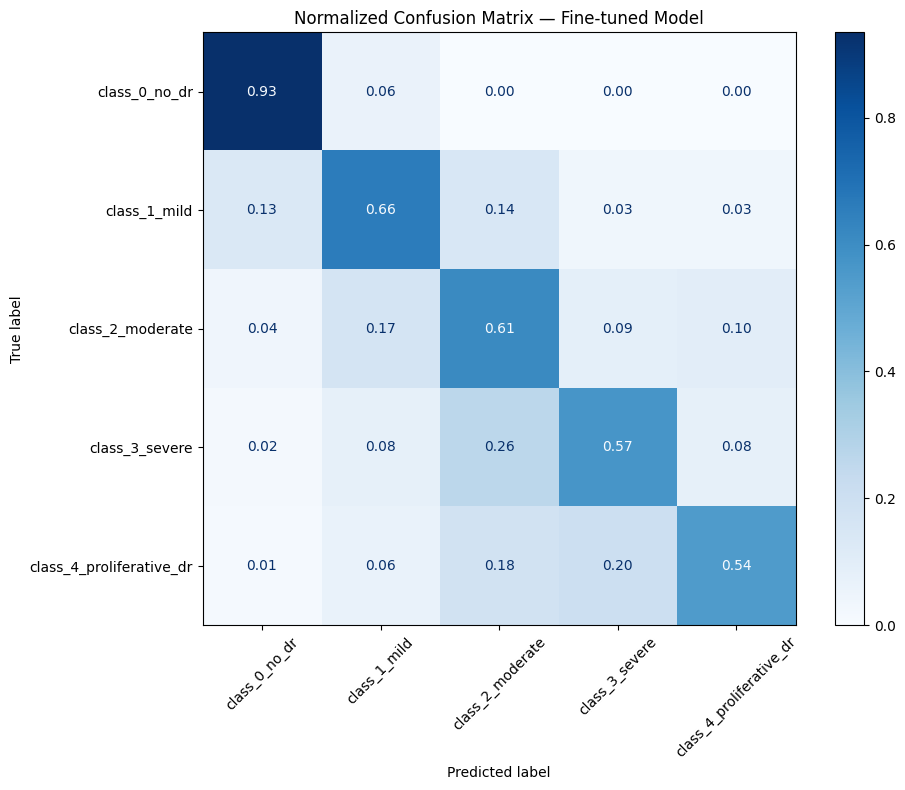

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict the validation dataset
y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = best_finetuned_model.predict(
        images, verbose=0
    )
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

# Normalize each row to percentages
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=True
)

plt.title("Normalized Confusion Matrix — Fine-tuned Model")
plt.tight_layout()
plt.show()

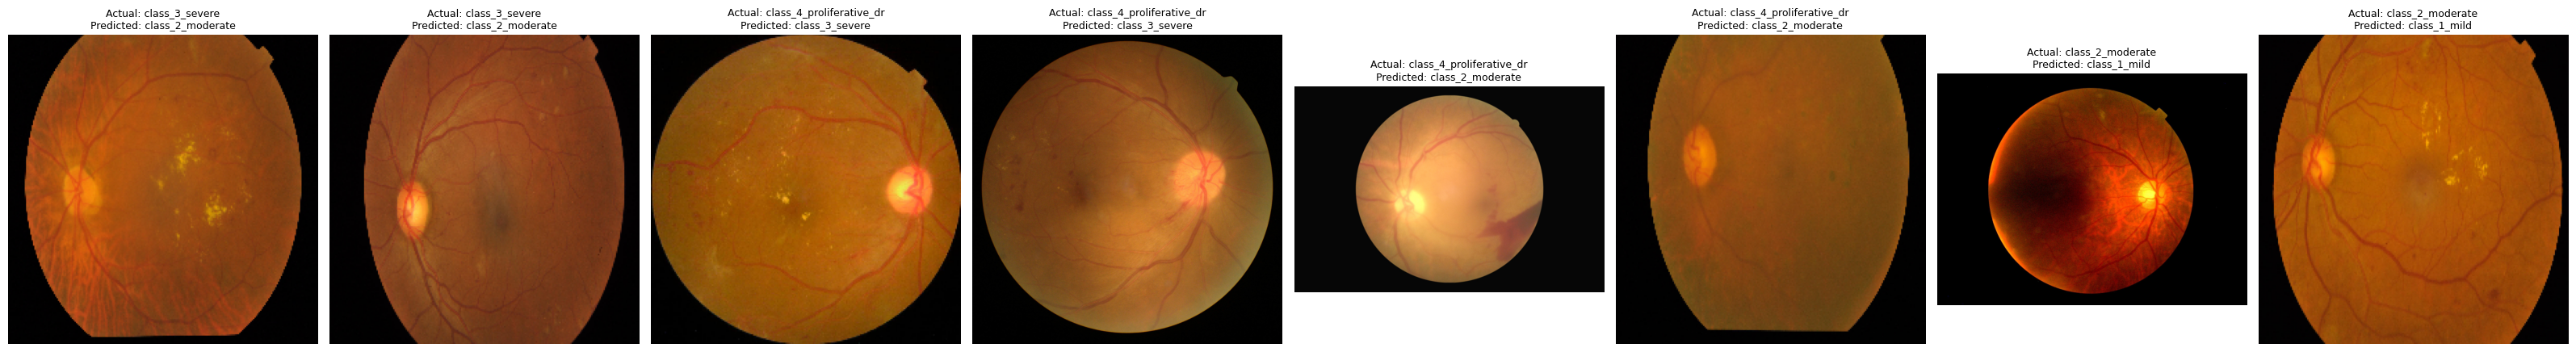

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# Match each validation image with its actual and predicted class
errors = val_df.reset_index(drop=True).copy()

errors["true_idx"] = y_true
errors["pred_idx"] = y_pred

errors["true_class"] = [
    class_names[i] for i in y_true
]
errors["pred_class"] = [
    class_names[i] for i in y_pred
]

# Select important types of mistakes to investigate
pairs_to_check = [
    ("class_3_severe", "class_2_moderate"),
    ("class_4_proliferative_dr", "class_3_severe"),
    ("class_4_proliferative_dr", "class_2_moderate"),
    ("class_2_moderate", "class_1_mild"),
]

samples = []

for actual, predicted in pairs_to_check:
    group = errors[
        (errors["true_class"] == actual)
        & (errors["pred_class"] == predicted)
    ]

    samples.append(group.head(2))

samples = pd.concat(samples).drop_duplicates()

if samples.empty:
    print("No matching errors found. Check y_true, y_pred, and class_names.")
else:
    fig, axes = plt.subplots(
        1, len(samples),
        figsize=(4 * len(samples), 5)
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, samples.iterrows()):
        image = Image.open(row["path"]).convert("RGB")

        ax.imshow(image)
        ax.set_title(
            f"Actual: {row['true_class']}\n"
            f"Predicted: {row['pred_class']}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# 1. Create gentle image augmentations
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="retina_augmentation")

# 2. Reuse the existing fine-tuned model
inputs = tf.keras.Input(shape=(224, 224, 3))
augmented_images = augmentation(inputs)
outputs = best_finetuned_model(augmented_images)

augmented_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="retina_augmentation_trial"
)

# 3. Compile with a small learning rate
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Save the best checkpoint separately
checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/RetinaExplain_AI/Models/retina_augmentation_trial.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# 5. Train using the existing data splits
history_aug = augmented_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

Epoch 1/12
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.7079 - loss: 0.9626
Epoch 1: val_loss improved from None to 0.86383, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_augmentation_trial.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_augmentation_trial.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 57s 168ms/step - accuracy: 0.7052 - loss: 0.9137 - val_accuracy: 0.6653 - val_loss: 0.8638 - learning_rate: 2.0000e-06
Epoch 2/12
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.7044 - loss: 0.8676
Epoch 2: val_loss did not improve from 0.86383
212/212 ━━━━━━━━━━━━━━━━━━━━ 30s 140ms/step - accuracy: 0.7020 - loss: 0.8672 - val_accuracy: 0.6267 - val_loss: 0.9344 - learning_rate: 2.0000e-06
Epoch 3/12
211/212 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.6991 - loss: 0.8725
Epoch 3: val_loss did not improve from 0.86383

Epoch 3: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
212/212 ━━━

In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, classification_report

def evaluate_model(model, dataset, model_name):
    y_true = []
    y_pred = []

    for images, labels in dataset:
        scores = model.predict(images, verbose=0)

        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(scores, axis=1))

    print(f"\n{'=' * 20} {model_name} {'=' * 20}")

    print(
        "Validation accuracy:",
        round(accuracy_score(y_true, y_pred) * 100, 2),
        "%"
    )

    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            digits=3,
            zero_division=0
        )
    )

    return y_true, y_pred


# Original fine-tuned model
baseline_true, baseline_pred = evaluate_model(
    best_finetuned_model,
    val_ds,
    "Original Fine-tuned Model"
)

# Augmentation experiment
aug_true, aug_pred = evaluate_model(
    augmented_model,
    val_ds,
    "Augmentation Experiment"
)


==================== Original Fine-tuned Model ====================
Validation accuracy: 66.53 %
                          precision    recall  f1-score   support

           class_0_no_dr      0.971     0.771     0.860       306
            class_1_mild      0.329     0.857     0.476        91
        class_2_moderate      0.724     0.524     0.608       185
          class_3_severe      0.554     0.554     0.554        65
class_4_proliferative_dr      0.766     0.456     0.571        79

                accuracy                          0.665       726
               macro avg      0.669     0.632     0.614       726
            weighted avg      0.768     0.665     0.689       726


==================== Augmentation Experiment ====================
Validation accuracy: 66.53 %
                          precision    recall  f1-score   support

           class_0_no_dr      0.971     0.771     0.860       306
            class_1_mild      0.329     0.857     0.476        91
        cl

In [ ]:

import os
import tensorflow as tf

# Original model saved before the augmentation experiment
baseline_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras"
)

# Checkpoint saved during the augmentation experiment
trial_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "retina_augmentation_trial.keras"
)

# Use the earlier fine-tuning checkpoint if the named copy is missing
if not os.path.exists(baseline_path):
    baseline_path = (
        "/content/drive/MyDrive/RetinaExplain_AI/Models/"
        "retina_efficientnetb0_v2_finetuned.keras"
    )

# Confirm both files exist before loading
assert os.path.exists(baseline_path), (
    f"Original model not found: {baseline_path}"
)
assert os.path.exists(trial_path), (
    f"Augmentation checkpoint not found: {trial_path}"
)

# Reload independent models from disk
baseline_model = tf.keras.models.load_model(baseline_path)
augmentation_trial_model = tf.keras.models.load_model(trial_path)

print("Models loaded independently.")
print("Baseline:", baseline_path)
print("Augmentation:", trial_path)

# Evaluate both on the same validation data
baseline_true, baseline_pred = evaluate_model(
    baseline_model,
    val_ds,
    "Saved Original Fine-tuned Model"
)

trial_true, trial_pred = evaluate_model(
    augmentation_trial_model,
    val_ds,
    "Saved Augmentation Checkpoint"
)

Models loaded independently.
Baseline: /content/drive/MyDrive/RetinaExplain_AI/Models/RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras
Augmentation: /content/drive/MyDrive/RetinaExplain_AI/Models/retina_augmentation_trial.keras

==================== Saved Original Fine-tuned Model ====================
Validation accuracy: 74.24 %
                          precision    recall  f1-score   support

           class_0_no_dr      0.932     0.935     0.933       306
            class_1_mild      0.504     0.659     0.571        91
        class_2_moderate      0.715     0.611     0.659       185
          class_3_severe      0.507     0.569     0.536        65
class_4_proliferative_dr      0.623     0.544     0.581        79

                accuracy                          0.742       726
               macro avg      0.656     0.664     0.656       726
            weighted avg      0.751     0.742     0.744       726


==================== Saved Augmentation Checkpoint ===

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# 1. Make an independent copy of our best saved model
trial_core = tf.keras.models.clone_model(baseline_model)
trial_core.set_weights(baseline_model.get_weights())

# 2. Keep the same fine-tuning strategy:
#    last 30 EfficientNet layers may train, earlier layers stay frozen.
backbone = trial_core.get_layer("efficientnetb0")
backbone.trainable = True

for layer in backbone.layers[:-30]:
    layer.trainable = False

# Batch normalization layers remain frozen for stability.
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 3. Use only gentle augmentation
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02)
], name="gentle_augmentation")

inputs = tf.keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
outputs = trial_core(x)

gentle_model = Model(
    inputs,
    outputs,
    name="retina_gentle_augmentation"
)

# 4. Compile with a small learning rate
gentle_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Check starting performance before training
print("Validation performance before training:")
gentle_model.evaluate(val_ds, verbose=1)

# 6. Save this experiment separately
callbacks = [
    ModelCheckpoint(
        "/content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# 7. Train the independent trial
history_gentle = gentle_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=callbacks
)

Validation performance before training:
46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 97ms/step - accuracy: 0.6129 - loss: 1.0818
Epoch 1/12
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.6432 - loss: 1.2360
Epoch 1: val_loss improved from None to 0.99460, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 40s 139ms/step - accuracy: 0.6450 - loss: 1.1899 - val_accuracy: 0.6212 - val_loss: 0.9946 - learning_rate: 1.0000e-06
Epoch 2/12
211/212 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.6565 - loss: 1.0568
Epoch 2: val_loss improved from 0.99460 to 0.96451, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 31s 144ms

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

baseline_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras"
)

# A. Reload the original baseline from disk
reference_model = tf.keras.models.load_model(baseline_path)

baseline_results = reference_model.evaluate(
    val_ds, verbose=0, return_dict=True
)

print("Saved baseline:")
print({k: round(float(v), 4) for k, v in baseline_results.items()})

# B. Create an independent copy with the same initial weights
trial_core = tf.keras.models.clone_model(reference_model)
trial_core.set_weights(reference_model.get_weights())

# C. Add augmentation layers without training
augmentation_check = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02)
])

inputs = tf.keras.Input(shape=(224, 224, 3))
x = augmentation_check(inputs)
outputs = trial_core(x)

check_model = Model(inputs, outputs)

# D. Evaluate before making any weight updates
check_results = check_model.evaluate(
    val_ds, verbose=0, return_dict=True
)

print("\nFresh augmented copy, before training:")
print({k: round(float(v), 4) for k, v in check_results.items()})

Saved baseline:
{'accuracy': 0.7424, 'loss': 0.7098}


ValueError: You must call `compile()` before using the model.

In [ ]:
# Compile the diagnostic model
check_model.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate without training or changing the model's weights
check_results = check_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

print("\nFresh augmented copy, before training:")
print({
    key: round(float(value), 4)
    for key, value in check_results.items()
})

46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 146ms/step - accuracy: 0.6129 - loss: 1.0818

Fresh augmented copy, before training:
{'accuracy': 0.6129, 'loss': 1.0818}


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

baseline_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras"
)

# 1. Load a separate copy directly from the saved model file
trial_core = tf.keras.models.load_model(
    baseline_path,
    compile=False
)

# 2. Confirm the baseline performance
reference_model = tf.keras.models.load_model(
    baseline_path,
    compile=False
)
reference_model.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Saved baseline:")
reference_model.evaluate(val_ds, verbose=1)

# 3. First create a wrapper WITHOUT augmentation
inputs = tf.keras.Input(shape=(224, 224, 3))
outputs = trial_core(inputs)

plain_wrapper = Model(inputs, outputs)
plain_wrapper.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nDirectly loaded model inside a wrapper:")
plain_wrapper.evaluate(val_ds, verbose=1)

# 4. Compare predictions on the exact same batch
images, labels = next(iter(val_ds))

original_predictions = reference_model.predict(
    images, verbose=0
)
wrapper_predictions = plain_wrapper.predict(
    images, verbose=0
)

max_difference = tf.reduce_max(
    tf.abs(original_predictions - wrapper_predictions)
).numpy()

print("\nMaximum prediction difference:", max_difference)

Saved baseline:
46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 183ms/step - accuracy: 0.7424 - loss: 0.7098

Directly loaded model inside a wrapper:
46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 199ms/step - accuracy: 0.7424 - loss: 0.7098

Maximum prediction difference: 0.0


In [ ]:

# Add augmentation around the verified model
augmentation_check = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02)
], name="gentle_augmentation_check")

inputs = tf.keras.Input(shape=(224, 224, 3))
augmented_images = augmentation_check(inputs)
outputs = trial_core(augmented_images)

augmentation_check_model = Model(inputs, outputs)

augmentation_check_model.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate in inference mode: random augmentation should be inactive
print("Accuracy with augmentation layer in evaluation mode:")
augmentation_check_model.evaluate(val_ds, verbose=1)

# Compare predictions for the same batch
augmented_predictions = augmentation_check_model.predict(
    images, verbose=0
)

max_difference_aug = tf.reduce_max(
    tf.abs(original_predictions - augmented_predictions)
).numpy()

print("Maximum prediction difference:", max_difference_aug)

Accuracy with augmentation layer in evaluation mode:
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 133ms/step - accuracy: 0.7424 - loss: 0.7098


Maximum prediction difference: 7.003546e-07


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Path to our best saved baseline model
baseline_path = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "RetinaExplain_AI_Finetuned_ValAcc_74.24pct_ValLoss_0.70979.keras"
)

# Load two independent model instances
baseline_model = tf.keras.models.load_model(
    baseline_path, compile=False
)

trial_core = tf.keras.models.load_model(
    baseline_path, compile=False
)

print("Baseline model loaded.")
print("Experimental model loaded independently.")

print("Baseline parameters:", baseline_model.count_params())
print("Experimental parameters:", trial_core.count_params())

Baseline model loaded.
Experimental model loaded independently.
Baseline parameters: 4055976
Experimental parameters: 4055976


In [ ]:
baseline_predictions = baseline_model.predict(
    val_ds, verbose=0
)

trial_predictions = trial_core.predict(
    val_ds, verbose=0
)

max_difference = tf.reduce_max(
    tf.abs(baseline_predictions - trial_predictions)
).numpy()

print("Baseline vs experimental prediction difference:", max_difference)

Baseline vs experimental prediction difference: 0.0


In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam

# 1. Augmentation: applied during training only
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02)
], name="gentle_augmentation")

# 2. Create the input
inputs = tf.keras.Input(shape=(224, 224, 3))

# 3. Apply augmentation
augmented_images = augmentation(inputs)

# 4. Pass images through our independent model
outputs = trial_core(augmented_images)

# 5. Create the experimental model
augmentation_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="retina_gentle_augmentation_trial"
)

# 6. Compile for training
augmentation_model.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmentation model created.")
print("Baseline model remains separate.")

Augmentation model created.
Baseline model remains separate.


In [ ]:
# Evaluate the experimental model before training
results = augmentation_model.evaluate(
    val_ds,
    verbose=1
)

print("Validation loss:", results[0])
print("Validation accuracy:", results[1])

# Compare predictions on the same validation batch
images, labels = next(iter(val_ds))

baseline_batch_predictions = baseline_model.predict(
    images, verbose=0
)

augmentation_batch_predictions = augmentation_model.predict(
    images, verbose=0
)

difference = tf.reduce_max(
    tf.abs(
        baseline_batch_predictions -
        augmentation_batch_predictions
    )
).numpy()

print("Maximum prediction difference:", difference)

46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 132ms/step - accuracy: 0.7424 - loss: 0.7098
Validation loss: 0.709794282913208
Validation accuracy: 0.7424242496490479
Maximum prediction difference: 7.003546e-07


In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

trial_checkpoint = (
    "/content/drive/MyDrive/RetinaExplain_AI/Models/"
    "retina_gentle_augmentation_best.keras"
)

callbacks = [
    ModelCheckpoint(
        filepath=trial_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_aug = augmentation_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=callbacks
)


Epoch 1/10
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.7326 - loss: 0.8507
Epoch 1: val_loss improved from None to 0.76408, saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RetinaExplain_AI/Models/retina_gentle_augmentation_best.keras
212/212 ━━━━━━━━━━━━━━━━━━━━ 45s 148ms/step - accuracy: 0.7400 - loss: 0.8194 - val_accuracy: 0.7135 - val_loss: 0.7641 - learning_rate: 1.0000e-06
Epoch 2/10
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.7435 - loss: 0.7905
Epoch 2: val_loss did not improve from 0.76408
212/212 ━━━━━━━━━━━━━━━━━━━━ 28s 134ms/step - accuracy: 0.7359 - loss: 0.7921 - val_accuracy: 0.6997 - val_loss: 0.7933 - learning_rate: 1.0000e-06
Epoch 3/10
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.7511 - loss: 0.7925
Epoch 3: val_loss did not improve from 0.76408

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999949504855e-07